# Kalibrace multispektrální kamery: od DN k odrazivosti na skutečných snímcích

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/multispectral_calibration_altum_pt_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Kalibrace multispektrální kamery](https://openskylab.space/edu_viz_multispectral_calibration.html) · [English version](multispectral_calibration_altum_pt_en.ipynb)

Vizuál ukazuje, co s odrazivostí udělá mrak, náklon dronu, vinětace a malý panel. Tady projdeš celý řetězec na skutečných snímcích kamery MicaSense Altum-PT: snímek kalibračního panelu před letem a snímek z letu nad silnicí, ovocným sadem, suchou loukou a fóliovníkem. Všechny potřebné údaje (černá úroveň, vinětace, kalibrační koeficienty, odrazivost panelu, údaje senzoru osvětlení DLS 2) jsou uložené přímo v souborech TIFF.

**Cíl:** převést DN na radianci krok za krokem, z panelu spočítat kalibrační koeficient, porovnat odrazivost jen z panelu, jen z DLS a z obou dohromady, ukázat vliv vinětace, saturace a náklonu senzoru DLS a spočítat NDVI ze sesazených pásem.

**Data:** dva snímky (5 multispektrálních pásem) kamery MicaSense Altum-PT s DLS 2 z ukázkových dat MicaSense (repozitář micasense/imageprocessing, licence MIT): IMG_0000 (panel RP06, 15. 8. 2022 19:16 UTC) a IMG_0010 (let o 3 minuty později asi 97 m nad terénem), 48,51° s. š., 122,42° z. d. Altum-PT má i panchromatické pásmo 6 a termální pásmo 7, které tento notebook nepoužívá.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a snímky

In [1]:
import re, io, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from matplotlib.path import Path

BASE = "https://media.githubusercontent.com/media/micasense/imageprocessing/master/data/ALTUM-PT/"
def fetch(name, tries=5):
    for i in range(tries):
        try:
            r = requests.get(BASE + name, timeout=120); r.raise_for_status(); return r.content
        except requests.RequestException as e:
            print(name, type(e).__name__, "– zkusím znovu"); time.sleep(3 * (i + 1))
    raise RuntimeError("Snímky se nepodařilo stáhnout.")

def xmp_reader(raw):
    x = raw[raw.find(b"<x:xmpmeta"): raw.find(b"</x:xmpmeta>")].decode()
    def get(tag):
        m = re.search(rf"<{tag}>(.*?)</{tag}>", x, re.S)
        if not m: return None
        v = m.group(1)
        if "<rdf:li>" in v:
            return [float(s) for li in re.findall(r"<rdf:li>\s*([^<]+?)\s*</rdf:li>", v) for s in li.split(",")]
        try: return float(v)
        except ValueError: return v.strip()
    return get

def load(name):
    """Načte jedno pásmo: pole DN a slovník metadat z EXIF a XMP."""
    raw = fetch(name); im = Image.open(io.BytesIO(raw)); ex = im.getexif(); sub = ex.get_ifd(0x8769); g = xmp_reader(raw)
    m = dict(band=g("Camera:BandName"), wl=g("Camera:CentralWavelength"), exposure=float(sub[33434]), gain=sub.get(34867, 100) / 100,
             black=float(np.mean(ex[50714])), bits=ex[258], cal=g("MicaSense:RadiometricCalibration"),
             vig_c=g("Camera:VignettingCenter"), vig_p=g("Camera:VignettingPolynomial"),
             vig_2d=g("Camera:VignettingPolynomial2D"), vig_e=g("Camera:VignettingPolynomial2DName"),
             albedo=g("Camera:Albedo"), area=g("Camera:ReflectArea"), time=ex[306],
             E_h=g("DLS:HorizontalIrradiance"), E_sensor=g("DLS:SpectralIrradiance"), E_dir=g("DLS:DirectIrradiance"),
             E_sc=g("DLS:ScatteredIrradiance"), sun_el=g("DLS:SolarElevation"), sun_az=g("DLS:SolarAzimuth"),
             pitch=g("DLS:Pitch"), roll=g("DLS:Roll"))
    for k in ("E_h", "E_sensor", "E_dir", "E_sc"):
        m[k] = m[k] * 0.01            # DLS 2 ukládá µW/cm²/nm, převod na W/m²/nm (faktor 0,01 jako v knihovně MicaSense)
    return np.array(im).astype(float), m

def vig_factor(m, shape):
    """Násobek korekce vinětace V pro každý pixel: radiální polynom, nebo u novějších kamer 2D polynom (jako micasense/image.py)."""
    y, x = np.indices(shape)
    if m["vig_c"] is not None:
        return 1 / np.polyval(list(m["vig_p"])[::-1] + [1.0], np.hypot(x - m["vig_c"][0], y - m["vig_c"][1]))
    xv, yv = x / shape[1], y / shape[0]
    return 1 / sum(c * xv ** m["vig_e"][2 * i] * yv ** m["vig_e"][2 * i + 1] for i, c in enumerate(m["vig_2d"]))

def panel_shift(a, c):
    """Celopixelový posun snímku c proti a fázovou korelací."""
    f = np.fft.fft2(a - a.mean()) * np.conj(np.fft.fft2(c - c.mean())); cc = np.abs(np.fft.ifft2(f / (np.abs(f) + 1e-9)))
    dy, dx = np.unravel_index(cc.argmax(), cc.shape)
    return (dy - a.shape[0] if dy > a.shape[0] // 2 else dy, dx - a.shape[1] if dx > a.shape[1] // 2 else dx)

PANEL = {b: load(f"IMG_0000_{b}.tif") for b in range(1, 6)}
FLIGHT = {b: load(f"IMG_0010_{b}.tif") for b in range(1, 6)}
for b in PANEL:                     # když software kamery panel v některém pásmu nenašel, posuneme oblast z pásma 1
    if PANEL[b][1]["area"] is None:
        dy, dx = panel_shift(PANEL[1][0], PANEL[b][0])
        PANEL[b][1]["area"] = list((np.array(PANEL[1][1]["area"]).reshape(-1, 2) - [dx, dy]).ravel())
        print(f"pásmo {b}: oblast panelu chybí v metadatech, odvozena z pásma 1 posunem o {dx}, {dy} px")
    if PANEL[b][1]["albedo"] is None:          # chybí i odrazivost panelu: odhad interpolací podle vlnové délky z ostatních pásem
        known = sorted((PANEL[k][1]["wl"], PANEL[k][1]["albedo"]) for k in PANEL if PANEL[k][1]["albedo"] is not None)
        PANEL[b][1]["albedo"] = float(np.interp(PANEL[b][1]["wl"], *zip(*known)))
        print(f"pásmo {b}: odrazivost panelu chybí v metadatech, odhad interpolací {PANEL[b][1]['albedo']:.3f}")
print(pd.DataFrame({PANEL[b][1]["band"]: {"λ (nm)": PANEL[b][1]["wl"], "expozice panel (ms)": 1000 * PANEL[b][1]["exposure"],
      "expozice let (ms)": 1000 * FLIGHT[b][1]["exposure"], "odrazivost panelu": PANEL[b][1]["albedo"]} for b in PANEL}).round(3))
print("panel:", PANEL[1][1]["time"], " let:", FLIGHT[1][1]["time"], " (UTC)")

                        Blue    Green      Red      NIR  Red edge
λ (nm)               475.000  560.000  668.000  842.000   717.000
expozice panel (ms)    0.449    0.405    1.079    0.899     1.573
expozice let (ms)      1.708    1.214    1.753    1.393     1.079
odrazivost panelu      0.488    0.488    0.487    0.485     0.486
panel: 2022:08:15 19:16:11  let: 2022:08:15 19:18:54  (UTC)


## 2. Od DN k radianci

Model MicaSense (stejný jako v knihovně `micasense/image.py`):

L = V(r) · R(y) · (DN − černá úroveň) / (zisk · expozice) · a₁ / 2¹⁶

- černá úroveň: signál bez světla (tag BlackLevel),
- V(r) = 1 / (1 + k₀r + … + k₅r⁶): korekce vinětace podle vzdálenosti r od středu vinětace (novější kamery ukládají místo toho 2D polynom v souřadnicích x, y),
- R(y) = 1 / (1 + a₂ y / expozice − a₃ y): korekce podle řádku (snímač se čte po řádcích),
- a₁: radiometrický kalibrační koeficient z výroby. Výsledek je spektrální radiance ve W/m²/sr/nm.

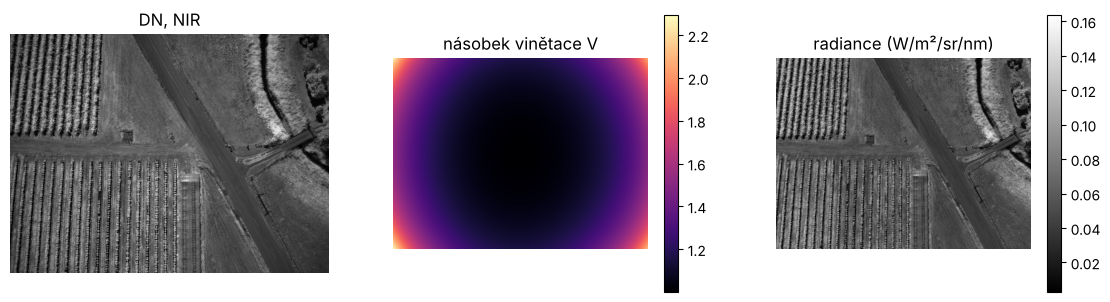

NIR: černá úroveň 240 DN, expozice 1.39 ms, zisk 1×
vinětace: střed ×1.00, roh ×2.28;  saturovaných pixelů 0.00 %


In [2]:
def radiance(dn, m, vignette=True):
    y, x = np.indices(dn.shape)
    a1, a2, a3 = m["cal"]
    V = vig_factor(m, dn.shape) if vignette else 1.0
    R = 1 / (1 + a2 * y / m["exposure"] - a3 * y)
    return np.clip(V * R * (dn - m["black"]), 0, None) / (m["gain"] * m["exposure"]) * a1 / 2 ** m["bits"]

BAND = 4                      # ◀ parametr: pásmo 1 modré, 2 zelené, 3 červené, 4 NIR, 5 red edge
dn, m = FLIGHT[BAND]
y, x = np.indices(dn.shape)
V = vig_factor(m, dn.shape)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].imshow(dn, cmap="gray"); ax[0].set_title(f"DN, {m['band']}")
im = ax[1].imshow(V, cmap="magma"); plt.colorbar(im, ax=ax[1]); ax[1].set_title("násobek vinětace V")
im = ax[2].imshow(radiance(dn, m), cmap="gray"); plt.colorbar(im, ax=ax[2]); ax[2].set_title("radiance (W/m²/sr/nm)")
for a in ax: a.axis("off")
plt.show()
sat = (dn >= 2 ** m["bits"] - 16).mean() * 100
print(f"{m['band']}: černá úroveň {m['black']:.0f} DN, expozice {m['exposure'] * 1000:.2f} ms, zisk {m['gain']:.0f}×")
print(f"vinětace: střed ×{V.min():.2f}, roh ×{V[0, 0]:.2f};  saturovaných pixelů {sat:.2f} %")

> **✏️ Úkol 1.** Projdi pásma 1 až 5. O kolik procent zesiluje korekce vinětace signál v rohu snímku a ve kterém pásmu nejvíc? Kolik procent pixelů je saturovaných a kde ve snímku jsou? Proč saturovaný pixel nejde opravit žádnou kalibrací a co s tím při letu uděláš?

*Tvoje odpověď:* 

## 3. Kalibrační panel

V metadatech snímku panelu je oblast uprostřed panelu, kterou na snímku našel software kamery (ReflectArea, čtyři rohy v pixelech), a jeho odrazivost v daném pásmu (Albedo) z kalibračního listu. Z průměrné radiance panelu L_p plyne koeficient k = ρ_panel / L_p a odrazivost každého pixelu ρ = k · L.

           pixelů     L_p  variabilita (%)  ρ_panel  k = ρ/L_p
Blue      13402.0  0.1341           1.7642   0.4884     3.6432
Green     13171.0  0.1493           1.7718   0.4877     3.2667
Red       13518.0  0.1481           1.9231   0.4868     3.2862
NIR       13518.0  0.0971           1.7677   0.4853     4.9992
Red edge  13347.0  0.1172           1.9143   0.4864     4.1495


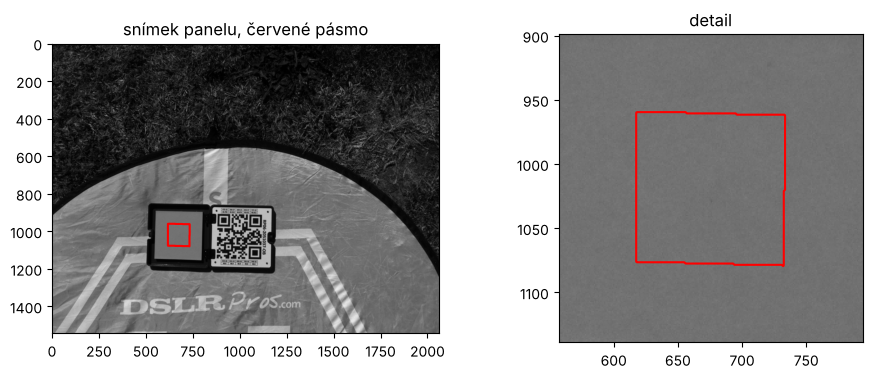

In [3]:
SHRINK = 1.0                  # ◀ parametr: zmenšení oblasti z metadat (1 = celá oblast, 0,3 = jen střed)
GROW_PX = 0                   # ◀ parametr: oblast naopak zvětšit o tolik pixelů (napodobí nepřesné vyznačení panelu)

def panel_mask(m, shrink=SHRINK, grow=GROW_PX):
    xy = np.array(m["area"]).reshape(-1, 2); c = xy.mean(axis=0)
    xy = c + (xy - c) * shrink + np.sign(xy - c) * grow
    yy, xx = np.indices(PANEL[1][0].shape)
    return Path(xy).contains_points(np.c_[xx.ravel(), yy.ravel()]).reshape(PANEL[1][0].shape)

rows = {}
for b, (dn, m) in PANEL.items():
    L = radiance(dn, m); msk = panel_mask(m)
    rows[m["band"]] = {"pixelů": msk.sum(), "L_p": L[msk].mean(), "variabilita (%)": 100 * L[msk].std() / L[msk].mean(),
                       "ρ_panel": m["albedo"], "k = ρ/L_p": m["albedo"] / L[msk].mean()}
panel_tab = pd.DataFrame(rows).T
print(panel_tab.round(4))
dn, m = PANEL[3]
xy = np.array(m["area"]).reshape(-1, 2)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(radiance(dn, m), cmap="gray"); ax[0].contour(panel_mask(m), [0.5], colors="r"); ax[0].set_title("snímek panelu, červené pásmo")
ax[1].imshow(radiance(dn, m), cmap="gray"); ax[1].contour(panel_mask(m), [0.5], colors="r")
ax[1].set_xlim(xy[:, 0].min() - 60, xy[:, 0].max() + 60); ax[1].set_ylim(xy[:, 1].max() + 60, xy[:, 1].min() - 60); ax[1].set_title("detail")
plt.show()

> **✏️ Úkol 2.** Nastav GROW_PX na 30, 60 a 90 (podívej se na detail, kam oblast sahá): jak se změní průměrná radiance panelu a koeficient k? O kolik procent by se tím posunula odrazivost celé mapy? Pak nastav SHRINK = 0,2: co se stane s variabilitou a proč? Proč se do průměru berou jen pixely ze středu panelu a proč musí být panel na snímku dost velký (kolik pixelů tu má)?

*Tvoje odpověď:* 

## 4. Senzor osvětlení DLS a jeho náklon

DLS měří ozáření na svou horní plochu. Když se dron nakloní ke Slunci, dopadá na senzor víc přímého záření, než kolik dopadá na vodorovný terén. DLS 2 proto rozkládá ozáření na přímou a rozptýlenou složku a přepočítává ho na vodorovnou plochu: E_vod = E_přímé · sin(výška Slunce) + E_rozptýlené.

In [4]:
TILT = 10                     # ◀ parametr: náklon senzoru DLS (°)
rows = {}
for b in range(1, 6):
    for name, (dn, m) in [("panel", PANEL[b]), ("let", FLIGHT[b])]:
        rows[(m["band"], name)] = {"E senzor": m["E_sensor"], "E vodorovné": m["E_h"], "přímé·sin(h)+rozptýlené": m["E_dir"] * np.sin(m["sun_el"]) + m["E_sc"],
                                   "náklon (°)": np.degrees(np.hypot(m["pitch"], m["roll"]))}
print(pd.DataFrame(rows).T.round(3))
m = FLIGHT[3][1]; el = m["sun_el"]
for direction, sign in [("ke Slunci", 1), ("od Slunce", -1)]:
    cos_g = np.sin(el) * np.cos(np.radians(TILT)) + sign * np.cos(el) * np.sin(np.radians(TILT))
    E_tilt = m["E_dir"] * cos_g + m["E_sc"]
    print(f"výška Slunce {np.degrees(el):.1f}°, náklon {TILT}° {direction}: senzor změří {E_tilt / m['E_h']:.3f}× vodorovné ozáření (bez korekce chyba odrazivosti {100 * (m['E_h'] / E_tilt - 1):+.1f} %)")

                E senzor  E vodorovné  přímé·sin(h)+rozptýlené  náklon (°)
Blue     panel     1.257        1.342                    1.342       1.624
         let       1.210        1.401                    1.401       6.633
Green    panel     1.154        1.225                    1.225       1.624
         let       1.110        1.280                    1.280       6.633
Red      panel     0.991        1.053                    1.053       1.624
         let       0.947        1.097                    1.097       6.633
NIR      panel     0.629        0.666                    0.666       1.624
         let       0.604        0.695                    0.695       6.633
Red edge panel     0.787        0.835                    0.835       1.624
         let       0.754        0.870                    0.870       6.633
výška Slunce 53.5°, náklon 10° ke Slunci: senzor změří 1.083× vodorovné ozáření (bez korekce chyba odrazivosti -7.7 %)
výška Slunce 53.5°, náklon 10° od Slunce: senzor změří 0

> **✏️ Úkol 3.** O kolik procent se mezi snímkem panelu a snímkem z letu změnilo vodorovné ozáření (časy snímků vypsala první buňka)? Jak velkou chybu odrazivosti způsobí náklon 10° a 20° ke Slunci a od Slunce? Proč je chyba při nízkém Slunci větší a proč pomáhá, když je rozptýlené složky hodně (zataženo)?

*Tvoje odpověď:* 

## 5. Tři způsoby kalibrace

- **jen panel:** ρ = k · L. Předpokládá, že se osvětlení od snímku panelu nezměnilo.
- **jen DLS:** ρ = π · L / E_vod. Spoléhá na tovární kalibraci kamery i DLS.
- **panel + DLS:** ρ = k · L · E_vod(panel) / E_vod(snímek). Panel určí absolutní úroveň, DLS sleduje změny osvětlení.

Kontrola: když metodu „jen DLS“ použijeme na samotný panel, měli bychom dostat jeho známou odrazivost.

                               Blue  Green    Red  Red edge    NIR
panel (kontrola) jen DLS      0.314  0.383  0.442     0.441  0.458
sad              jen DLS      0.010  0.032  0.015     0.109  0.290
                 jen panel    0.016  0.042  0.017     0.125  0.321
                 panel + DLS  0.015  0.040  0.016     0.120  0.307
silnice          jen DLS      0.086  0.122  0.154     0.160  0.182
                 jen panel    0.140  0.163  0.177     0.184  0.201
                 panel + DLS  0.134  0.156  0.170     0.177  0.192
suchá louka      jen DLS      0.038  0.073  0.122     0.155  0.237
                 jen panel    0.062  0.097  0.140     0.178  0.262
                 panel + DLS  0.060  0.093  0.134     0.171  0.251


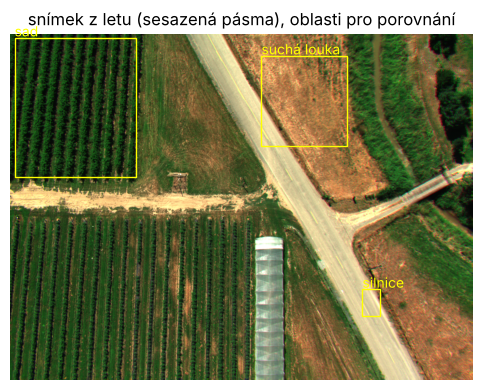

In [5]:
def shift_to(ref, img):
    """Celopixelový posun img vůči ref fázovou korelací gradientů (pásma má každé svůj objektiv)."""
    g = lambda a: np.hypot(*np.gradient(ndi.gaussian_filter(a, 1.5)))
    F = np.fft.fft2(g(ref)) * np.conj(np.fft.fft2(g(img))); c = np.fft.ifft2(F / (np.abs(F) + 1e-12)).real
    dy, dx = np.unravel_index(c.argmax(), c.shape)
    return (dy - c.shape[0] if dy > c.shape[0] // 2 else dy, dx - c.shape[1] if dx > c.shape[1] // 2 else dx)

L_fl = {b: radiance(*FLIGHT[b]) for b in FLIGHT}
shifts = {b: shift_to(L_fl[3], L_fl[b]) for b in FLIGHT}
L_al = {b: ndi.shift(L_fl[b], shifts[b], order=0, mode="nearest") for b in FLIGHT}
REGIONS = {"silnice": (slice(1140, 1260), slice(1570, 1650)), "suchá louka": (slice(100, 500), slice(1120, 1500)), "sad": (slice(20, 640), slice(20, 560))}  # ◀ parametr: oblasti (řádky, sloupce)
res = {}
for b in FLIGHT:
    mp, mf = PANEL[b][1], FLIGHT[b][1]; k = panel_tab.loc[mp["band"], "k = ρ/L_p"]
    methods = {"jen panel": k * L_al[b], "jen DLS": np.pi * L_al[b] / mf["E_h"], "panel + DLS": k * L_al[b] * mp["E_h"] / mf["E_h"]}
    for meth, rho in methods.items():
        for reg, (r, c) in REGIONS.items():
            res[(reg, meth, mp["band"])] = np.median(rho[r, c])
    res[("panel (kontrola)", "jen DLS", mp["band"])] = np.pi * panel_tab.loc[mp["band"], "L_p"] / mp["E_h"]
RHO = pd.Series(res).unstack()[["Blue", "Green", "Red", "Red edge", "NIR"]]
print(RHO.round(3))
fig, ax = plt.subplots(figsize=(11, 4.5))
rgb = np.dstack([L_al[3], L_al[2], L_al[1]]); ax.imshow(np.clip(rgb / np.percentile(rgb, 99), 0, 1))
for reg, (r, c) in REGIONS.items():
    ax.add_patch(plt.Rectangle((c.start, r.start), c.stop - c.start, r.stop - r.start, fill=False, color="yellow")); ax.text(c.start, r.start - 8, reg, color="yellow")
ax.set_title("snímek z letu (sesazená pásma), oblasti pro porovnání"); ax.axis("off"); plt.show()

> **✏️ Úkol 4.** Jakou odrazivost panelu dá metoda „jen DLS“ a o kolik procent se liší od kalibračního listu? Která metoda je tu nejspolehlivější a proč? O kolik se liší „jen panel“ a „panel + DLS“ a čím to je (vrať se ke kroku 4)? Odpovídají křivky silnice, suché louky a sadu tomu, co znáš ze spektrálních signatur?

*Tvoje odpověď:* 

## 6. NDVI a co s ním dělá kalibrace

NDVI = (ρ_NIR − ρ_R) / (ρ_NIR + ρ_R). Porovnáme NDVI z radiance (bez kalibrace), z kalibrace „panel + DLS“ a z kalibrace bez korekce vinětace.

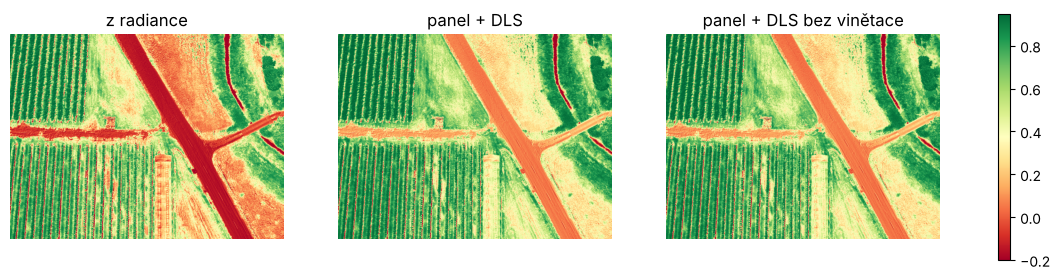

                      z radiance  panel + DLS  panel + DLS bez vinětace
silnice                   -0.154        0.054                     0.046
suchá louka                0.106        0.305                     0.298
sad                        0.852        0.900                     0.893
podíl NDVI ≥ 0.5 (%)      46.664       59.726                    58.999


In [6]:
NDVI_MIN = 0.5                # ◀ parametr: práh NDVI pro „vegetaci“
def calibrated(b, vignette=True):
    mp, mf = PANEL[b][1], FLIGHT[b][1]; k = panel_tab.loc[mp["band"], "k = ρ/L_p"]
    L = ndi.shift(radiance(*FLIGHT[b], vignette=vignette), shifts[b], order=0, mode="nearest")
    return k * L * mp["E_h"] / mf["E_h"]
nd = lambda nir, red: (nir - red) / (nir + red + 1e-9)
variants = {"z radiance": nd(L_al[4], L_al[3]), "panel + DLS": nd(calibrated(4), calibrated(3)),
            "panel + DLS bez vinětace": nd(calibrated(4, False), calibrated(3, False))}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, v) in zip(ax, variants.items()):
    im = a.imshow(v, cmap="RdYlGn", vmin=-0.2, vmax=0.95); a.set_title(name); a.axis("off")
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()
print(pd.DataFrame({name: {**{reg: np.median(v[r, c]) for reg, (r, c) in REGIONS.items()}, f"podíl NDVI ≥ {NDVI_MIN} (%)": 100 * (v >= NDVI_MIN).mean()}
                    for name, v in variants.items()}).round(3))

> **✏️ Úkol 5.** Proč se NDVI z radiance tolik liší od NDVI z odrazivosti, i když jde o stejný snímek? Proč vynechání korekce vinětace NDVI skoro nezmění, ale odrazivost v rozích ano (srovnej s krokem 2)? Jak by se změnil podíl vegetace, kdyby někdo prahoval NDVI z radiance?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Spolužáci mohou mít notebook pro jinou kameru (RedEdge-MX, Altum, Altum-PT). Porovnejte koeficient k z panelu, změnu ozáření mezi panelem a letem a rozdíl metod „jen DLS“ a „panel + DLS“. Liší se víc kamery, nebo podmínky osvětlení při letu?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Snímky a postup radiometrické kalibrace: MicaSense, Inc. (2017–2023). *imageprocessing* (licence MIT), https://github.com/micasense/imageprocessing, soubory data/ALTUM-PT/IMG_0000_*.tif a IMG_0010_*.tif a micasense/image.py (vinětace, radiance, odrazivost).
- MicaSense: RedEdge Camera Radiometric Calibration Model; Use of Calibrated Reflectance Panels for MicaSense Data (podpora MicaSense).
- Smith, G. M., Milton, E. J. (1999). The use of the empirical line method to calibrate remotely sensed data to reflectance. *International Journal of Remote Sensing* 20(13), 2653–2662.
- Přehled kalibrace multispektrálních a hyperspektrálních kamer na UAV: Aasen, H., Honkavaara, E., Lucieer, A., Zarco-Tejada, P. J. (2018). Quantitative remote sensing at ultra-high resolution with UAV spectroscopy. *Remote Sensing* 10(7), 1091.

### Jak citovat

OpenSkyLab (2026). Kalibrace multispektrální kamery: od DN k odrazivosti na skutečných snímcích [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/multispectral_calibration_altum_pt_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*